# 5. Descriptive Statistics and Model Visualisations

## Purpose

This notebook summarises the modelling dataset and visualises the
performance of Linear Regression 2.2.

It includes:

1. Descriptive statistics.
2. The distribution of goals scored.
3. Correlations between the predictors and target.
4. Actual versus predicted goals on the test set.
5. Test-set residuals.

The evaluation plots use predictions saved by Notebook 4. No new
model is fitted and no new train/test split is created.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Locate the project folder.
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

processed_dir = PROJECT_ROOT / "data" / "processed"
report_dir = PROJECT_ROOT / "report"

# Create the output folder if it does not already exist.
report_dir.mkdir(parents=True, exist_ok=True)

# Load the modelling dataset and the saved test predictions.
df = pd.read_csv(
    processed_dir / "worldcup2026_regression_2_2.csv",
    parse_dates=["match_date"]
)

predictions = pd.read_csv(
    processed_dir / "regression_2_2_test_predictions.csv",
    parse_dates=["match_date"]
)

metrics = pd.read_csv(
    processed_dir / "regression_2_2_metrics.csv"
)

predictors = [
    "team_avg_goals_scored_before",
    "team_avg_goals_conceded_before",
    "team_goal_difference_before",
    "team_win_rate_before",
    "opponent_avg_goals_scored_before",
    "opponent_avg_goals_conceded_before",
    "opponent_goal_difference_before",
    "opponent_win_rate_before"
]

# Check that the saved test observations match the modelling dataset.
assert len(df) == 208
assert not predictions.duplicated(["match_id", "team"]).any()

score_check = predictions.merge(
    df[["match_id", "team", "goals_scored"]],
    on=["match_id", "team"],
    how="left",
    validate="one_to_one"
)

assert score_check["goals_scored"].notna().all()
assert score_check["actual_goals"].eq(
    score_check["goals_scored"]
).all()

# Check the saved residual definition.
assert np.allclose(
    predictions["residual"],
    predictions["actual_goals"] - predictions["predicted_goals"]
)

sns.set_theme(style="whitegrid")

print("Modelling observations:", len(df))
print("Test observations:", len(predictions))
print("Saved prediction checks passed.")

Modelling observations: 208
Test observations: 44
Saved prediction checks passed.


## 5.1 Descriptive Statistics

We summarise the target and eight predictors using the count, mean,
standard deviation, minimum, quartiles, median, and maximum.

This table describes the complete tournament dataset. It is used for
exploration only; it does not change the fitted model or its predictors.

The zero-history convention means opening-match predictor values are
zero. These values should not be interpreted as evidence of zero
attacking or defensive ability.

In [2]:
# Summarise the target and all eight explanatory variables.
summary = df[["goals_scored"] + predictors].describe().T

# Use clearer column names for the saved summary table.
summary = summary.rename(columns={
    "count": "observations",
    "std": "standard_deviation",
    "25%": "first_quartile",
    "50%": "median",
    "75%": "third_quartile"
})

display(summary.round(3))

# Save full-precision values for later reporting.
summary.to_csv(
    processed_dir / "regression_2_2_descriptive_statistics.csv",
    index_label="variable"
)

print("Saved descriptive statistics.")

,observations,mean,standard_deviation,min,first_quartile,median,third_quartile,max
goals_scored,208.0,1.481,1.393,0.0,0.0,1.00,2.000,7.0
team_avg_goals_scored_before,208.0,1.329,1.213,0.0,0.0,1.00,2.000,7.0
team_avg_goals_conceded_before,208.0,0.977,1.101,0.0,0.0,1.00,1.271,7.0
team_goal_difference_before,208.0,1.490,3.696,-8.0,0.0,0.00,4.000,14.0
team_win_rate_before,208.0,0.348,0.389,0.0,0.0,0.25,0.667,1.0
opponent_avg_goals_scored_before,208.0,1.329,1.213,0.0,0.0,1.00,2.000,7.0
opponent_avg_goals_conceded_before,208.0,0.977,1.101,0.0,0.0,1.00,1.271,7.0
opponent_goal_difference_before,208.0,1.490,3.696,-8.0,0.0,0.00,4.000,14.0
opponent_win_rate_before,208.0,0.348,0.389,0.0,0.0,0.25,0.667,1.0


Saved descriptive statistics.


## 5.2 Distribution of Goals Scored

This chart counts how frequently each goal total occurred across the
208 team-match observations.

It describes observed goals, not predicted goals. We use it to identify
common score totals and unusually high-scoring observations.

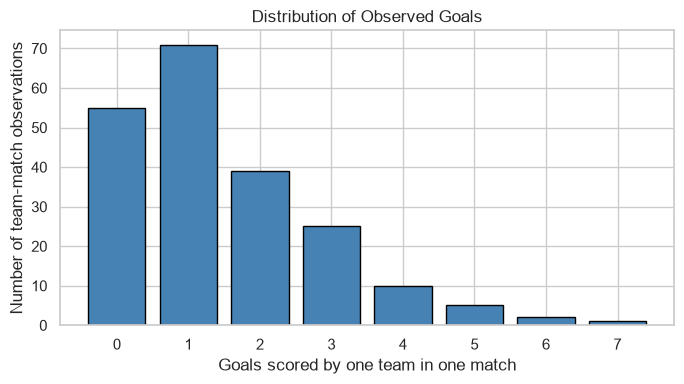

Most frequent goal total: 1
Maximum observed goals: 7


In [3]:
# Count observations for every integer goal total.
goal_counts = (
    df["goals_scored"]
    .value_counts()
    .reindex(
        range(int(df["goals_scored"].max()) + 1),
        fill_value=0
    )
    .sort_index()
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    goal_counts.index,
    goal_counts.values,
    color="steelblue",
    edgecolor="black"
)

ax.set(
    xlabel="Goals scored by one team in one match",
    ylabel="Number of team-match observations",
    title="Distribution of Observed Goals"
)

ax.set_xticks(goal_counts.index)
fig.tight_layout()

fig.savefig(
    report_dir / "goals_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Most frequent goal total:", goal_counts.idxmax())
print("Maximum observed goals:", df["goals_scored"].max())

## 5.3 Predictor Correlations in the Training Data

We inspect correlations using training observations only.

Pearson correlation measures linear association. Values close to +1
or -1 indicate strong positive or negative linear association.

Large correlations between explanatory variables may make individual
regression coefficients difficult to interpret. Pairwise correlations
alone do not establish whether the full model has multicollinearity.

Correlation does not imply causation.

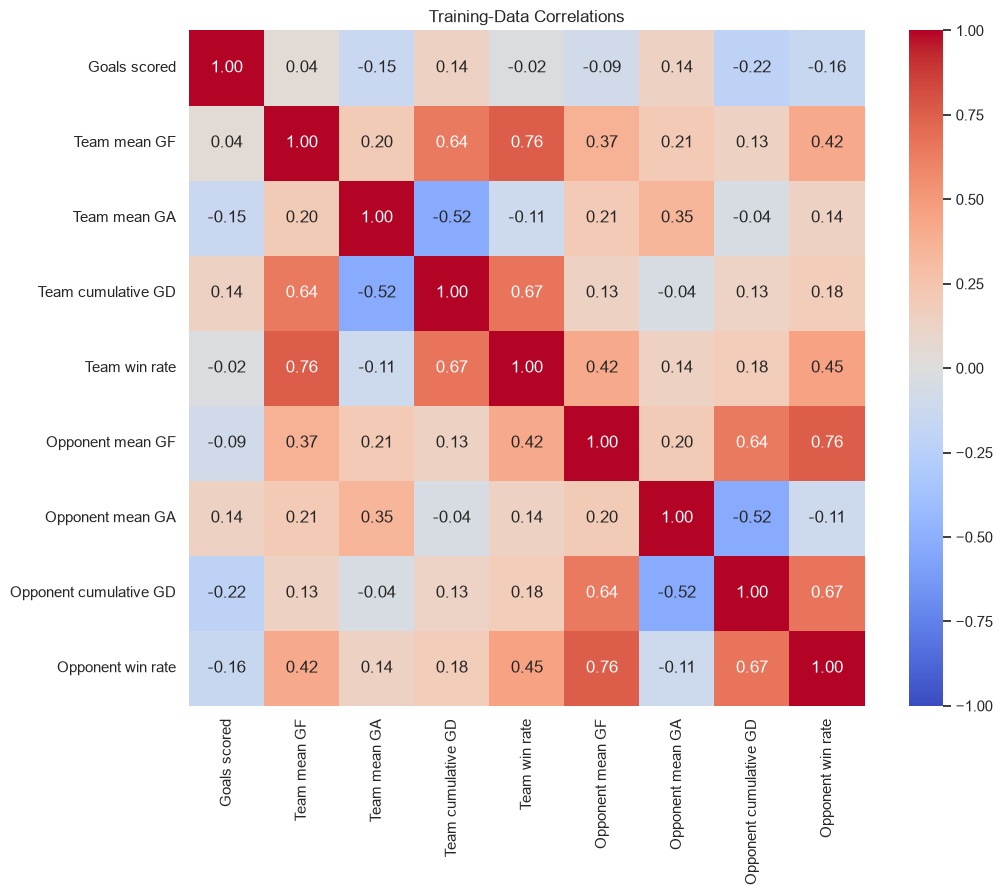

In [4]:
# Use the partition assignments saved by Notebook 4.
partitions = pd.read_csv(
    processed_dir / "regression_2_2_partitions.csv"
)

# Attach each observation's saved training/test assignment.
labelled_df = df.merge(
    partitions[["match_id", "team", "partition"]],
    on=["match_id", "team"],
    how="left",
    validate="one_to_one"
)

assert labelled_df["partition"].notna().all()

training_data = labelled_df.loc[
    labelled_df["partition"].eq("Training")
].copy()

# Calculate correlations without using the test observations.
correlation = training_data[
    ["goals_scored"] + predictors
].corr()

# Short labels keep the chart readable.
short_labels = [
    "Goals scored",
    "Team mean GF",
    "Team mean GA",
    "Team cumulative GD",
    "Team win rate",
    "Opponent mean GF",
    "Opponent mean GA",
    "Opponent cumulative GD",
    "Opponent win rate"
]

plot_correlation = correlation.copy()
plot_correlation.index = short_labels
plot_correlation.columns = short_labels

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    plot_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=ax
)

ax.set_title("Training-Data Correlations")
fig.tight_layout()

fig.savefig(
    report_dir / "training_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save the matrix using the original variable names.
correlation.to_csv(
    processed_dir / "regression_2_2_training_correlations.csv"
)

## 5.4 Actual Versus Predicted Test Goals

Each point represents one held-out team-match observation.

The horizontal axis shows actual goals and the vertical axis shows
predicted goals. Points on the diagonal reference line represent
perfect predictions.

Points above the line indicate overprediction; points below it
indicate underprediction.

Predictions remain continuous and are not rounded or clipped.
Some observations may overlap because teams can have identical
actual and predicted values.

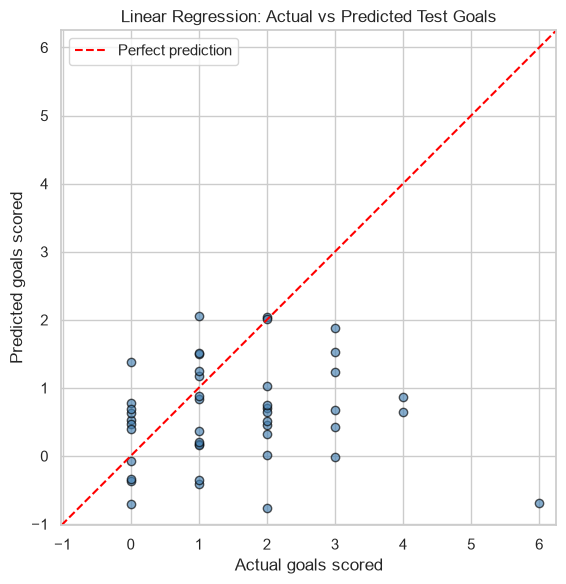

Test observations plotted: 44
Negative predictions: 9


In [5]:
# Use only the predictions saved from the chronological test set.
actual = predictions["actual_goals"]
predicted = predictions["predicted_goals"]

# Include negative predictions in the chart if any exist.
lower = min(0, actual.min(), predicted.min()) - 0.25
upper = max(actual.max(), predicted.max()) + 0.25

fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(
    actual,
    predicted,
    alpha=0.65,
    color="steelblue",
    edgecolors="black"
)

ax.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--",
    color="red",
    label="Perfect prediction"
)

ax.set(
    xlabel="Actual goals scored",
    ylabel="Predicted goals scored",
    title="Linear Regression: Actual vs Predicted Test Goals",
    xlim=(lower, upper),
    ylim=(lower, upper)
)

ax.set_aspect("equal", adjustable="box")
ax.legend()
fig.tight_layout()

fig.savefig(
    report_dir / "actual_vs_predicted_goals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Test observations plotted:", len(predictions))
print("Negative predictions:", int(predicted.lt(0).sum()))

## 5.5 Test-Set Residuals

Residual is calculated as:

actual goals minus predicted goals.

A positive residual means the model underpredicted goals. A negative
residual means it overpredicted goals.

We plot residuals against predicted goals to examine systematic error
and whether error spread changes across predictions.

This is a visual diagnostic, not proof that regression assumptions
are satisfied. The two team observations within a match may also
be dependent.

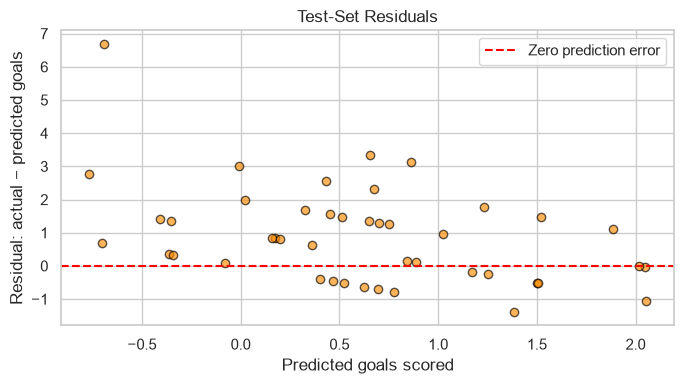

Mean test residual: 0.908
Largest absolute test error: 6.691


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    predictions["predicted_goals"],
    predictions["residual"],
    alpha=0.65,
    color="darkorange",
    edgecolors="black"
)

ax.axhline(
    0,
    color="red",
    linestyle="--",
    label="Zero prediction error"
)

ax.set(
    xlabel="Predicted goals scored",
    ylabel="Residual: actual − predicted goals",
    title="Test-Set Residuals"
)

ax.legend()
fig.tight_layout()

fig.savefig(
    report_dir / "test_residual_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mean test residual:", round(predictions["residual"].mean(), 3))
print(
    "Largest absolute test error:",
    round(predictions["residual"].abs().max(), 3)
)

## 5.6 Compare the Regression with the Baseline

We compare test MAE and RMSE for the linear regression and the
training-mean baseline.

Both models were evaluated on the same held-out observations.
Lower values indicate smaller prediction errors.

The baseline provides a reference for deciding whether the regression's
eight predictors improved predictive performance.

,model,partition,R2,MAE,RMSE
1,Linear regression,Test,-0.705,1.246,1.727
2,Training-mean baseline,Test,-0.002,1.065,1.324


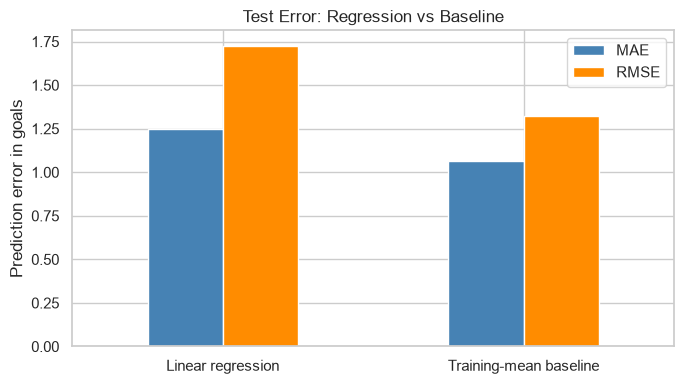

In [7]:
# Display the metrics calculated in Notebook 4.
test_metrics = metrics.loc[
    metrics["partition"].eq("Test")
].copy()

display(test_metrics.round(3))

# Compare test errors without fitting either model again.
error_comparison = test_metrics.set_index("model")[["MAE", "RMSE"]]

ax = error_comparison.plot(
    kind="bar",
    figsize=(7, 4),
    rot=0,
    color=["steelblue", "darkorange"]
)

ax.set(
    xlabel="",
    ylabel="Prediction error in goals",
    title="Test Error: Regression vs Baseline"
)

ax.figure.tight_layout()

ax.figure.savefig(
    report_dir / "test_error_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5.7 Interpretation and Limitations

After inspecting the outputs, record the findings in our own words:

1. Which observed goal totals were most common?
2. Which training predictors were strongly correlated?
3. Did the model systematically overpredict or underpredict any scores?
4. Were any predictions negative?
5. Did the regression outperform the baseline on test MAE and RMSE?

Important limitations include:

- Goals are non-negative counts, but linear regression predicts
  unrestricted continuous values.
- Opening-match historical predictors use the zero-history convention.
- The predictors describe related aspects of team form.
- The chronological test period contains later tournament matches,
  so its stage composition differs from the training period.
- Two observations from the same match are not necessarily independent.
- This evaluation uses one tournament and one chronological holdout,
  which limits conclusions about general performance.

In [8]:
# Confirm that every intended chart was created successfully.
expected_charts = [
    "goals_distribution.png",
    "training_correlation_heatmap.png",
    "actual_vs_predicted_goals.png",
    "test_residual_plot.png",
    "test_error_comparison.png"
]

for filename in expected_charts:
    chart_path = report_dir / filename

    assert chart_path.is_file(), f"Missing chart: {filename}"
    assert chart_path.stat().st_size > 0, f"Empty chart: {filename}"

    print("Saved:", filename)

print("Notebook 5 outputs are complete.")

Saved: goals_distribution.png
Saved: training_correlation_heatmap.png
Saved: actual_vs_predicted_goals.png
Saved: test_residual_plot.png
Saved: test_error_comparison.png
Notebook 5 outputs are complete.
